In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Lasso, LassoCV, Ridge, RidgeCV
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

In [2]:
data = pd.read_csv('data_2026.csv')

In [3]:
train = data.iloc[:200,:]
test = data.iloc[200:, :]

In [4]:
X_train = train.drop(columns='y')
y_train = train['y']

X_test = test.drop(columns='y')
y_test = test['y']

scaler = StandardScaler()
X_train = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

Exercise 1

Lasso

In [26]:
alphas = np.logspace(-4, 2, 100)

lasso_cv = LassoCV(
    alphas=alphas,
    cv=5,
    max_iter=100_000
).fit(X_train, y_train)

alpha = lasso_cv.alpha_
lasso_lambda = len(X_train) * alpha

print(f"sklearn alpha: {alpha}")
print(f"Equivalent course lambda: {lasso_lambda}")

sklearn alpha: 0.01
Equivalent course lambda: 2.0


In [27]:
# sklearn uses alpha = lambda / n in its normalized objective.
lasso = Lasso(
    alpha=lasso_lambda / len(X_train),
    max_iter=100_000
).fit(X_train, y_train)

PCR

In [7]:
pcr = make_pipeline(PCA(), LinearRegression())

search = GridSearchCV(
    pcr,
    {"pca__n_components": range(1, X_train.shape[1] + 1)},
    scoring="neg_mean_squared_error",
    cv=5
).fit(X_train, y_train)

k = search.best_params_["pca__n_components"]
print('Number of components for PCR:', k)

pcr = search.best_estimator_

Number of components for PCR: 79


In [8]:
pca_k = PCA(n_components=k).fit(X_train)
pca_10 = PCA(n_components=10).fit(X_train)
pca_9 = PCA(n_components=9).fit(X_train)
share = pca_k.explained_variance_ratio_.sum()
print(f'Explained variance by PCR with {k} components:', share)
print(f'Explained variance by PCR with 10 components:', pca_10.explained_variance_ratio_.sum())
print(f'Explained variance by PCR with 9 components:', pca_9.explained_variance_ratio_.sum())

Explained variance by PCR with 79 components: 0.999696988392451
Explained variance by PCR with 10 components: 0.9772420158194381
Explained variance by PCR with 9 components: 0.9359631054543122


Exercise 2

Outliers with residuals


In [9]:
lasso_residuals = y_train - lasso.predict(X_train)
pcr_residuals = y_train - pcr.predict(X_train)

residuals_df = pd.DataFrame({
    'Lasso': lasso_residuals,
    'PCR': pcr_residuals
    })

In [10]:
std_residuals = (residuals_df - residuals_df.mean(axis=0))/residuals_df.std(axis=0)

threshold = 2
lasso_outliers = np.where(np.abs(std_residuals['Lasso']) > threshold)[0]
pcr_outliers = np.where(np.abs(std_residuals['PCR']) > threshold)[0]

Outliers with clustering

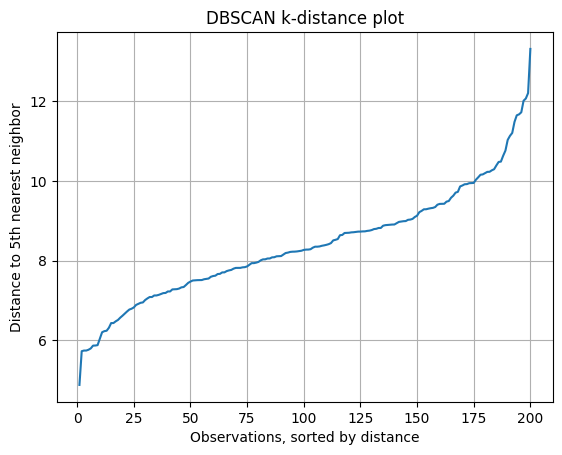

In [11]:
# min_samples=5 - distance to the 5th neighbor, including the point itself
nn = NearestNeighbors(n_neighbors=5).fit(X_train)
distances, _ = nn.kneighbors(X_train)
k_dist = sorted(distances[:, -1])

plt.plot(range(1, len(k_dist) + 1), k_dist)
plt.xlabel("Observations, sorted by distance")
plt.ylabel("Distance to 5th nearest neighbor")
plt.title("DBSCAN k-distance plot")
plt.grid(True)
plt.savefig('dbscan_k_distance.png', dpi=300, bbox_inches='tight')
plt.show()

In [12]:
for eps in [9.5, 10.0, 10.5, 11.0]:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_train)
    n_noise = np.sum(labels == -1)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print("eps:", eps, ", clusters:", n_clusters, ", noise points:", n_noise)

eps: 9.5 , clusters: 1 , noise points: 10
eps: 10.0 , clusters: 1 , noise points: 6
eps: 10.5 , clusters: 1 , noise points: 5
eps: 11.0 , clusters: 1 , noise points: 4


Pick `eps = 10`

In [13]:
eps = 10
labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_train)
outlier_indices = np.flatnonzero(labels == -1)

In [14]:
print(f"Lasso outliers: {lasso_outliers}")
print(f"PCR outliers: {pcr_outliers}")
print(f"DBSCAN outliers: {outlier_indices}")

Lasso outliers: [ 50 103 127]
PCR outliers: [ 50 103 127]
DBSCAN outliers: [ 27  31  68 172 175 193]


Exercise 3

Removing the identified outliers

In [15]:
# Combine outlier indices from all detection methods
all_outlier_indices = np.unique(
    np.concatenate([lasso_outliers, pcr_outliers, outlier_indices])
)

data_cleaned = data.drop(index=all_outlier_indices)

X_train_cleaned = data_cleaned.iloc[:-100, :].drop(columns='y')
y_train_cleaned = data_cleaned.iloc[:-100, :]['y']

X_train_cleaned = pd.DataFrame(
    scaler.fit_transform(X_train_cleaned),
    columns=X_train_cleaned.columns,
    index=X_train_cleaned.index
)

# Scale the test set using the refitted training scaler
X_test_cleaned = pd.DataFrame(
    scaler.transform(test.drop(columns="y")),
    columns=test.drop(columns="y").columns,
    index=test.index
)


print(f"Removed {len(all_outlier_indices)} observations: {all_outlier_indices}")
print(f"New training shape: {X_train_cleaned.shape}")

Removed 9 observations: [ 27  31  50  68 103 127 172 175 193]
New training shape: (191, 100)


In [16]:
# Refit Lasso on the cleaned training data
lasso_cv_cleaned = LassoCV(
    alphas=alphas,
    cv=5,
    max_iter=100_000
).fit(X_train_cleaned, y_train_cleaned)

alpha_cleaned = lasso_cv_cleaned.alpha_
lasso_cleaned = Lasso(
    alpha=alpha_cleaned,
    max_iter=100_000
).fit(X_train_cleaned, y_train_cleaned)

# Refit PCR on the cleaned training data
pcr_search_cleaned = GridSearchCV(
    make_pipeline(PCA(), LinearRegression()),
    {"pca__n_components": range(1, X_train_cleaned.shape[1] + 1)},
    scoring="neg_mean_squared_error",
    cv=5
).fit(X_train_cleaned, y_train_cleaned)

pcr_cleaned = pcr_search_cleaned.best_estimator_
k_cleaned = pcr_search_cleaned.best_params_["pca__n_components"]

print(f"Cleaned Lasso alpha: {alpha_cleaned}")
print(f"Cleaned Lasso lambda: {len(X_train_cleaned) * alpha_cleaned}")
print(f"Cleaned PCR components: {k_cleaned}")

Cleaned Lasso alpha: 0.008697490026177835
Cleaned Lasso lambda: 1.6612205949999663
Cleaned PCR components: 95


Exercise 5

Sequential heursitic

Lasso

In [25]:
alpha = 0.01
n = X_train.shape[0]
q = 3 # 3 observations removed each iteration
trimmed_lasso = Lasso(alpha=alpha, max_iter=100_000)
X_train_lasso = X_train.copy()
y_train_lasso = y_train.copy()
trimmed_lasso.fit(X_train_lasso, y_train_lasso)
residuals = np.zeros(y_train_lasso.shape[0])
keep_indices_k = None  # Initialize as an empty Series
obj_value_k = np.inf  # Initialize as infinity
i = 0
while True:
    print(f"Iteration {i + 1}")
    print(f"Current training shape: {X_train_lasso.shape}")
    residuals = y_train - trimmed_lasso.predict(X_train)
    residuals_k = y_train_lasso - trimmed_lasso.predict(X_train_lasso)
    squared_residuals = residuals ** 2

    keep_indices = squared_residuals.nsmallest(n-q).index
    print(f"Indices of the {q} largest residuals: {X_train.index.difference(keep_indices)}")
    obj_value = (
        np.sum(residuals_k**2) / (2 * y_train_lasso.shape[0])
        + alpha * np.sum(np.abs(trimmed_lasso.coef_))
    )

    obj_improv = obj_value < obj_value_k

    if keep_indices_k is not None and np.array_equal(
        np.sort(keep_indices), np.sort(keep_indices_k)):
        print("Same observations removed as previous iteration. Stopping.")
        break
    elif not obj_improv:
        print("Objective value did not improve. Stopping.")
        break



    X_train_lasso = X_train.drop(index=X_train.index.difference(keep_indices), axis=0)
    y_train_lasso = y_train.drop(index=X_train.index.difference(keep_indices), axis=0)
    trimmed_lasso.fit(X_train_lasso, y_train_lasso)
    keep_indices_k = keep_indices
    obj_value_k = obj_value
    i += 1

print(f"Final training shape after iterative removal: {X_train_lasso.shape}")
print(f"Removed observations: {X_train.index.difference(keep_indices_k)}")
    

Iteration 1
Current training shape: (200, 100)
Indices of the 3 largest residuals: Index([50, 103, 127], dtype='int64')
Iteration 2
Current training shape: (197, 100)
Indices of the 3 largest residuals: Index([50, 103, 127], dtype='int64')
Same observations removed as previous iteration. Stopping.
Final training shape after iterative removal: (197, 100)
Removed observations: Index([50, 103, 127], dtype='int64')


PCA

In [18]:
k = 79
q = 6
n = X_train.shape[0]
X_train_pcr = X_train.copy()
y_train_pcr = y_train.copy()
trimmed_pca = PCA(n_components=k).fit(X_train_pcr)
Z = trimmed_pca.transform(X_train)
X_hat = pd.DataFrame(
    trimmed_pca.inverse_transform(Z),
    index=X_train.index,
    columns=X_train.columns
)
keep_indices_k = None
i = 0
while True:
    print(f"Iteration {i + 1}")
    print(f"Current training shape: {X_train_pcr.shape}")
    projection_errors = ((X_train - X_hat) ** 2).sum(axis=1)
    keep_indices = projection_errors.nsmallest(n - q).index
    print(f"Indices of the {q} biggest projection errors: {X_train.index.difference(keep_indices)}")

    if keep_indices_k is not None and np.array_equal(
        np.sort(keep_indices), np.sort(keep_indices_k)
    ):
        print("Same observations removed as previous iteration. Stopping.")
        break

    X_train_pcr = X_train.loc[keep_indices].copy()
    y_train_pcr = y_train.loc[keep_indices].copy()
    trimmed_pca = PCA(n_components=k).fit(X_train_pcr)
    Z = trimmed_pca.transform(X_train)
    X_hat = pd.DataFrame(
        trimmed_pca.inverse_transform(Z),
        index=X_train.index,
        columns=X_train.columns
    )
    keep_indices_k = keep_indices
    i += 1

Z_cleaned = trimmed_pca.transform(X_train_pcr)
print(f"Final PCA training shape after iterative removal: {X_train_pcr.shape}")
print(f"Removed observations: {X_train.index.difference(keep_indices_k)}")
print(f"Final OLS training shape after iterative removal: {Z_cleaned.shape}")

Iteration 1
Current training shape: (200, 100)
Indices of the 6 biggest projection errors: Index([10, 107, 109, 113, 187, 191], dtype='int64')
Iteration 2
Current training shape: (194, 100)
Indices of the 6 biggest projection errors: Index([10, 107, 109, 113, 187, 191], dtype='int64')
Same observations removed as previous iteration. Stopping.
Final PCA training shape after iterative removal: (194, 100)
Removed observations: Index([10, 107, 109, 113, 187, 191], dtype='int64')
Final OLS training shape after iterative removal: (194, 79)


In [20]:
# Fit PCR on the final trimmed subset: PCA followed by OLS.
trimmed_pcr = make_pipeline(
    PCA(n_components=k),
    LinearRegression()
)
trimmed_pcr.fit(X_train_pcr, y_train_pcr)
print(f"Trimmed PCR fitted on {X_train_pcr.shape[0]} observations using {k} components.")

Trimmed PCR fitted on 194 observations using 79 components.


Exercise 6

Combining clustering -> PCA -> lasso

Kind of like a "PCLR" - Principal Component Lasso Regression

The clustering was applied with DBSCAN when removing the outliers from the data

In [21]:
pclr = make_pipeline(
    PCA(n_components=0.999),
    Lasso(max_iter=100_000)
)

pclr_search = GridSearchCV(
    pclr,
    {"lasso__alpha": alphas,},
    scoring="neg_mean_squared_error",
    cv=5
)

pclr_search.fit(X_train_cleaned, y_train_cleaned)
pclr_best = pclr_search.best_estimator_
print("Best alpha for PCLR with 99.9% explained variance:", pclr_search.best_params_)
print("Equivalent course lambda: ", X_train_cleaned.shape[0] * pclr_search.best_params_["lasso__alpha"])

Best alpha for PCLR with 99.9% explained variance: {'lasso__alpha': np.float64(0.01519911082952933)}
Equivalent course lambda:  2.903030168440102


Exercise 7

In [44]:
models = {
    "Q1 Lasso": (lasso, X_test),
    "Q1 PCR": (pcr, X_test),
    "Q3 cleaned Lasso": (lasso_cleaned, X_test_cleaned),
    "Q3 cleaned PCR": (pcr_cleaned, X_test_cleaned),
    "Q5 trimmed Lasso": (trimmed_lasso, X_test),
    "Q5 trimmed PCR": (trimmed_pcr, X_test),
    "Q6 PCLR": (pclr_best, X_test_cleaned),
}

In [45]:
rng = np.random.default_rng(2026)
results = []

for b in range(1, 31):
    idx = rng.choice(len(y_test), size=30, replace=True)
    y_b = y_test.iloc[idx].to_numpy()

    for name, (model, X_eval) in models.items():
        pred = model.predict(X_eval.iloc[idx])
        results.append({
            "bootstrap": b,
            "model": name,
            "RMSE": np.sqrt(np.mean((y_b - pred) ** 2)),
            "MAE": np.mean(np.abs(y_b - pred)),
        })
        
results = pd.DataFrame(results)

RMSE                           MAE                    
                      mean       std    median      mean       std    median
model                                                                       
Q1 Lasso          2.294954  0.309021  2.285461  1.888233  0.262632  1.842022
Q1 PCR            3.629689  0.573201  3.586868  2.880198  0.483304  2.903824
Q3 cleaned Lasso  1.162064  0.161205  1.180952  0.929140  0.143452  0.950762
Q3 cleaned PCR    1.671937  0.281054  1.577691  1.342640  0.230306  1.278857
Q5 trimmed Lasso  1.167739  0.165199  1.206147  0.929456  0.148551  0.948873
Q5 trimmed PCR    3.712184  0.585304  3.769437  2.909209  0.530353  2.944559
Q6 PCLR           2.940053  0.445672  2.945943  2.471645  0.342265  2.466397

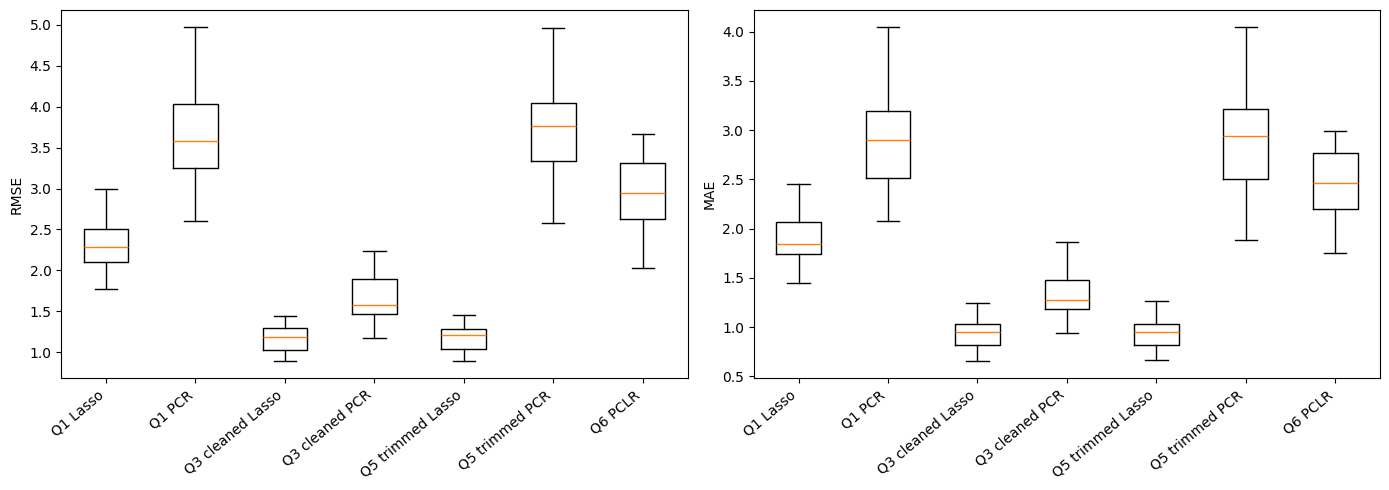

In [46]:
display(results.groupby("model")[["RMSE", "MAE"]].agg(["mean", "std", "median"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
names = list(models)

for ax, metric in zip(axes, ["RMSE", "MAE"]):
    vals = [
        results.loc[results["model"] == name, metric].to_numpy()
        for name in names
    ]
    ax.boxplot(vals)
    ax.set_xticks(range(1, len(names) + 1))
    ax.set_xticklabels(names, rotation=40, ha="right")
    ax.set_ylabel(metric)

plt.tight_layout()

In [47]:
lasso_models = {
    "Q1 Lasso": lasso,
    "Q3 cleaned Lasso": lasso_cleaned,
    "Q5 trimmed Lasso": trimmed_lasso,
    "Q6 PCLR": pclr_best.named_steps["lasso"],
}

nonzero_table = pd.DataFrame([
    {
        "Model": name,
        "Coefficient type": "PCs" if name == "Q6 PCLR" else "Original features",
        "Nonzero coefficients": int(np.count_nonzero(model.coef_)),
        "Total coefficients": len(model.coef_),
        "Fraction of nonzero coefficients": np.count_nonzero(model.coef_) / len(model.coef_),
    }
    for name, model in lasso_models.items()
])

display(nonzero_table)

,Model,Coefficient type,Nonzero coefficients,Total coefficients,Fraction of nonzero coefficients
0,Q1 Lasso,Original features,58,100,0.580000
1,Q3 cleaned Lasso,Original features,41,100,0.410000
2,Q5 trimmed Lasso,Original features,36,100,0.360000
3,Q6 PCLR,PCs,56,61,0.918033


Exercise 9

                             Quantity    Value
            Training observations (n)      200
                         Features (p)      100
                                  p/n     0.50
                            Rank of X      100
                Condition number of X    181.4
        Feature pairs with |r| >= 0.8 240/4950
Largest absolute pairwise correlation    0.993


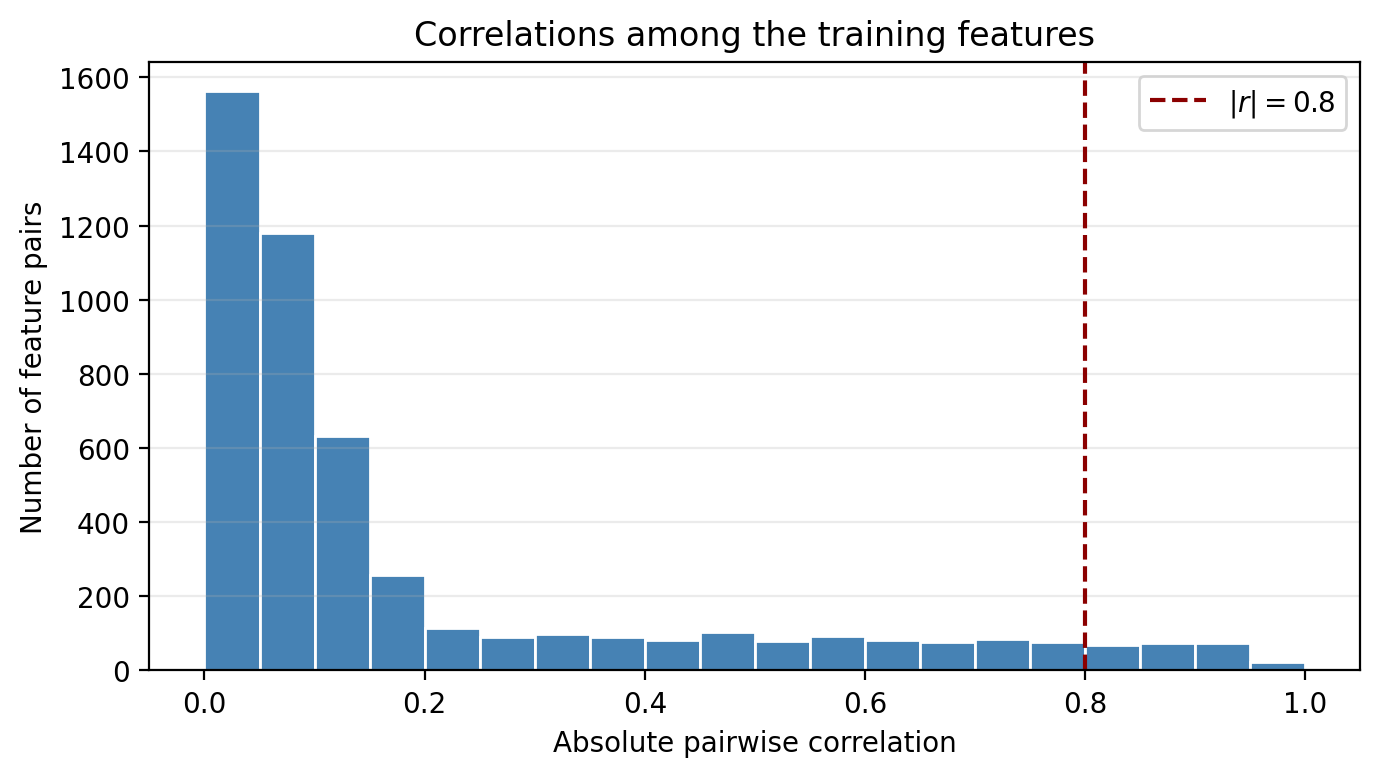

In [49]:
# Dataset diagnostics for considering OLS and ridge.
from pathlib import Path

n, p = X_train.shape
X_array = X_train.to_numpy()
pairwise_abs_corr = np.abs(
    X_train.corr().to_numpy()[np.triu_indices(p, k=1)]
)
rank_X = np.linalg.matrix_rank(X_array)
condition_number_X = np.linalg.cond(X_array)
n_high_corr = int(np.sum(pairwise_abs_corr >= 0.8))

q9_summary = pd.DataFrame({
    "Quantity": [
        "Training observations (n)",
        "Features (p)",
        "p/n",
        "Rank of X",
        "Condition number of X",
        "Feature pairs with |r| >= 0.8",
        "Largest absolute pairwise correlation",
    ],
    "Value": [
        n,
        p,
        f"{p / n:.2f}",
        rank_X,
        f"{condition_number_X:.1f}",
        f"{n_high_corr}/{len(pairwise_abs_corr)}",
        f"{pairwise_abs_corr.max():.3f}",
    ],
})
print(q9_summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(pairwise_abs_corr, bins=np.linspace(0, 1, 21), color="steelblue", edgecolor="white")
ax.axvline(0.8, color="darkred", linestyle="--", label=r"$|r|=0.8$")
ax.set_xlabel("Absolute pairwise correlation")
ax.set_ylabel("Number of feature pairs")
ax.set_title("Correlations among the training features")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
q9_plot_path = Path("../6aad5eee42e0cccfd1864263/images/q9_abs_correlations.png")
q9_plot_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(q9_plot_path, dpi=200, bbox_inches="tight")
plt.show()
